# Kredito įsipareigojimų nevykdymo rizikos prognozė

**Meila Andriuškevičiūtė · DISfm-26 · Intelektualiosios sistemos**

Ši užrašinė yra mokslinė eksperimento dalis. Gynimo svetainė: `streamlit run svetaine.py`.

**Hipotezė.** XGBoost dėl netiesinių ryšių ir požymių sąveikų pranoks logistinę regresiją pagal PR-AUC, išlaikydamas priimtiną kalibraciją.

**Viena komanda visam eksperimentui:** `python run_experiment.py` (sėkla 42).


## 1. Duomenys ir skaidymas

UCI *Default of Credit Card Clients*: 30 000 klientų, 6 636 default atvejai (22,12 %).
Stratifikuotas 70/15/15. Preprocessing parametrai skaičiuojami tik mokymo imtyje.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data import load_dataset
from src.preprocess import stratified_split
from src.config import ARTIFACTS_DIR, RANDOM_SEED
from src.formulas import logistic_probability, linear_score, brier_score, total_error_cost, decision_from_threshold

df, quality = load_dataset()
split = stratified_split(df, seed=RANDOM_SEED)
results = json.loads((ARTIFACTS_DIR / "results.json").read_text(encoding="utf-8"))
pd.DataFrame([quality])[["n_rows", "n_default", "default_rate", "duplicate_rows"]]


,n_rows,n_default,default_rate,duplicate_rows
0,30000,6636,0.2212,0


In [2]:
print("Mokymas", len(split.X_train), "Validavimas", len(split.X_val), "Testas", len(split.X_test))
print("Default dažniai:", float(split.y_train.mean()), float(split.y_val.mean()), float(split.y_test.mean()))
split.X_train.head()


Mokymas 21000 Validavimas 4500 Testas 4500
Default dažniai: 0.22123809523809523 0.22111111111111112 0.22111111111111112


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,220000,2,2,1,35,0,0,0,0,0,...,93311,67900,64150,6000,10626,3600,3100,4000,6000,0
1,200000,1,1,1,41,-1,-1,-1,-1,-1,...,5440,-2,796,1390,0,5462,0,798,1394,3600
2,180000,2,1,1,30,0,0,0,0,0,...,128002,127286,119733,116705,10000,6007,4304,4241,4200,4250
3,200000,2,2,2,23,0,-1,-1,-1,0,...,-849,107555,108177,110506,4938,473,110000,3899,4100,8000
4,160000,2,2,2,29,-1,-1,-1,-1,-1,...,1086,1874,2920,0,2108,1086,1874,2920,0,1222


## 2. Formulės ir kodas

Logistinė regresija:

$$z_i = \beta_0 + \beta_1 x_{i1} + \cdots + \beta_p x_{ip}$$

$$\hat p_i = \frac{1}{1 + e^{-z_i}}$$

Brier score: \(\mathrm{BS} = \frac{1}{N}\sum_i (\hat p_i - y_i)^2\)

Kaina: \(\mathrm{Cost}(t) = C_{FN}\cdot FN(t) + C_{FP}\cdot FP(t)\)

Implementacija: `src/formulas.py`. Žemiau – skaitiška patikra, kad formulė sutampa su `sklearn`.


In [3]:
from src.models import logistic_formula_check
import joblib

bundle = joblib.load(ARTIFACTS_DIR / "models" / "Logistinė_regresija.joblib")
check = logistic_formula_check(bundle["model"], split.X_val, n=5)
pd.DataFrame(check)


,z,p_formula,p_sklearn,max_abs_diff
0,-0.187463,0.453271,0.453271,0.0
1,-0.121399,0.469688,0.469688,0.0
2,-0.707693,0.330109,0.330109,0.0
3,-0.872798,0.294673,0.294673,0.0
4,-1.913155,0.128627,0.128627,0.0


## 3. Modelių palyginimas (tas pats skaidymas)

Hiperparametrai rinkti tik validavime. Testas naudotas vieną kartą.


In [4]:
summary = pd.read_csv(ARTIFACTS_DIR / "tables" / "model_comparison.csv")
summary[["model", "pr_auc", "roc_auc", "brier", "ece", "cost", "threshold", "calibration"]]


,model,pr_auc,roc_auc,brier,ece,cost,threshold,calibration
0,XGBoost,0.542992,0.782029,0.134295,1.763097e-02,2529.0,0.175,isotonic
1,Random Forest,0.533276,0.778196,0.136278,1.515201e-02,2520.0,0.150,isotonic
2,Logistinė regresija,0.479487,0.715304,0.142591,1.273479e-02,2896.0,0.175,isotonic
3,Bendras dažnis,0.221111,0.500000,0.172221,2.775558e-17,3505.0,0.050,isotonic


**pr_curves.png**

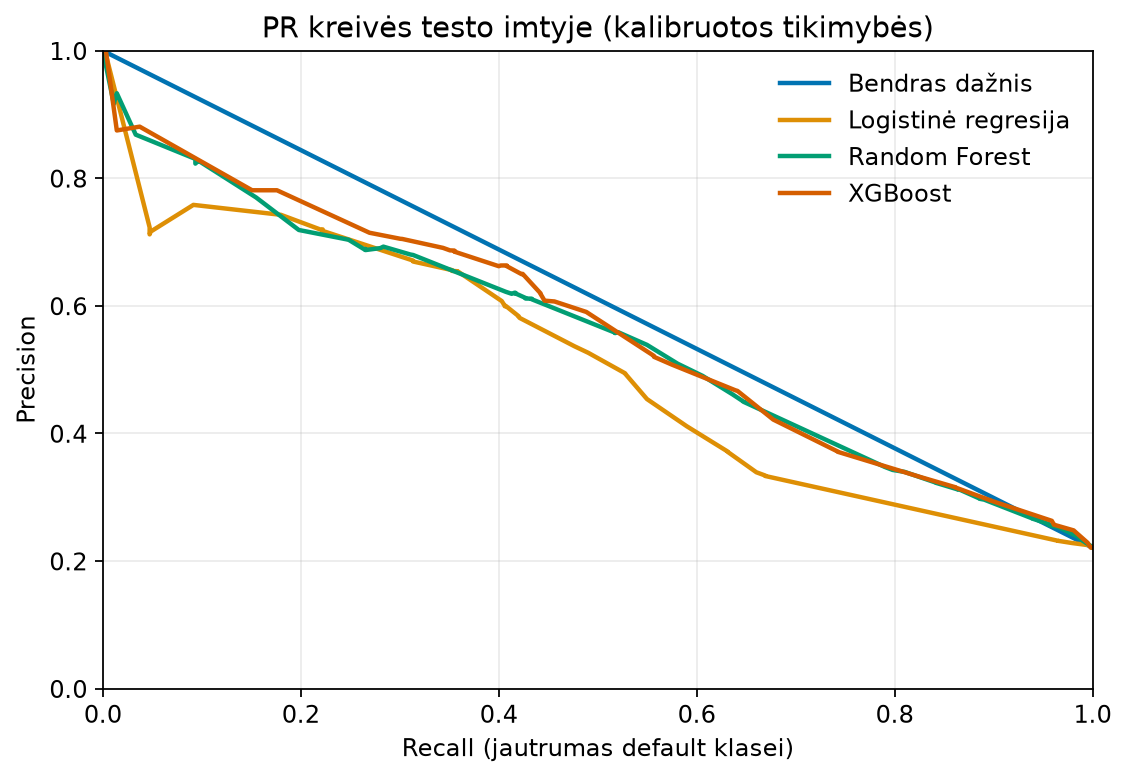

**model_bars.png**

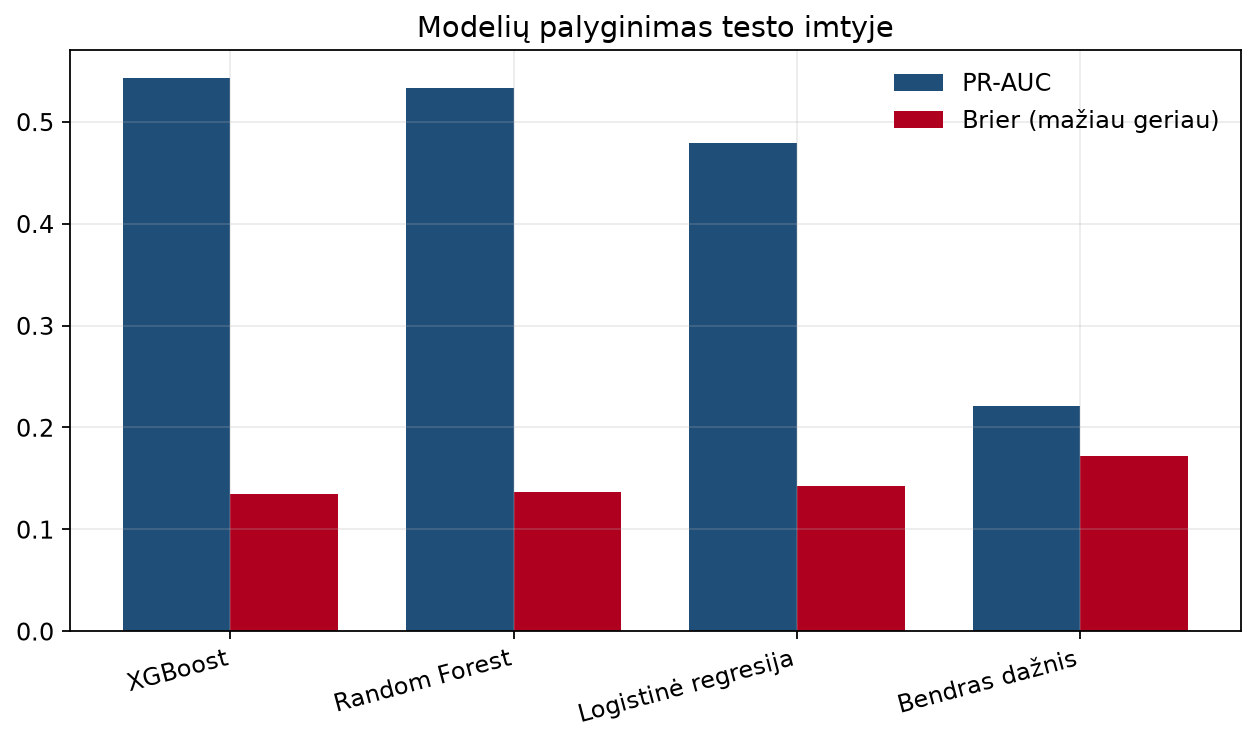

**calibration.png**

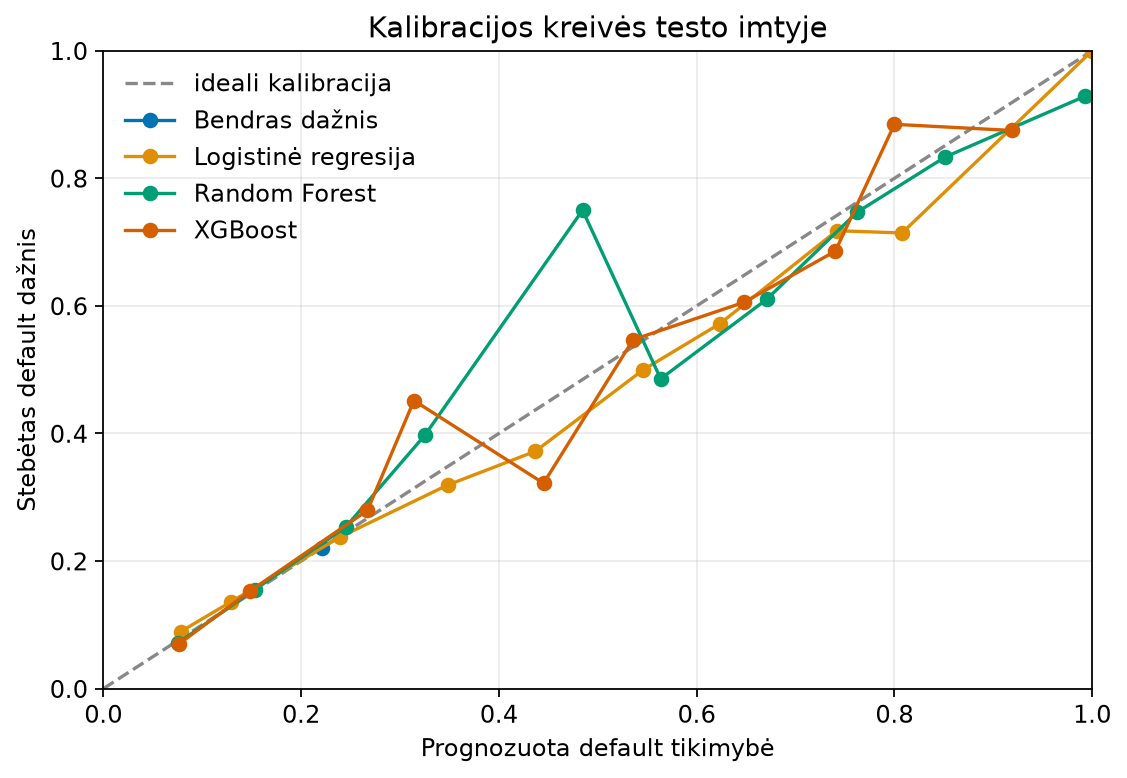

**cost_curve.png**

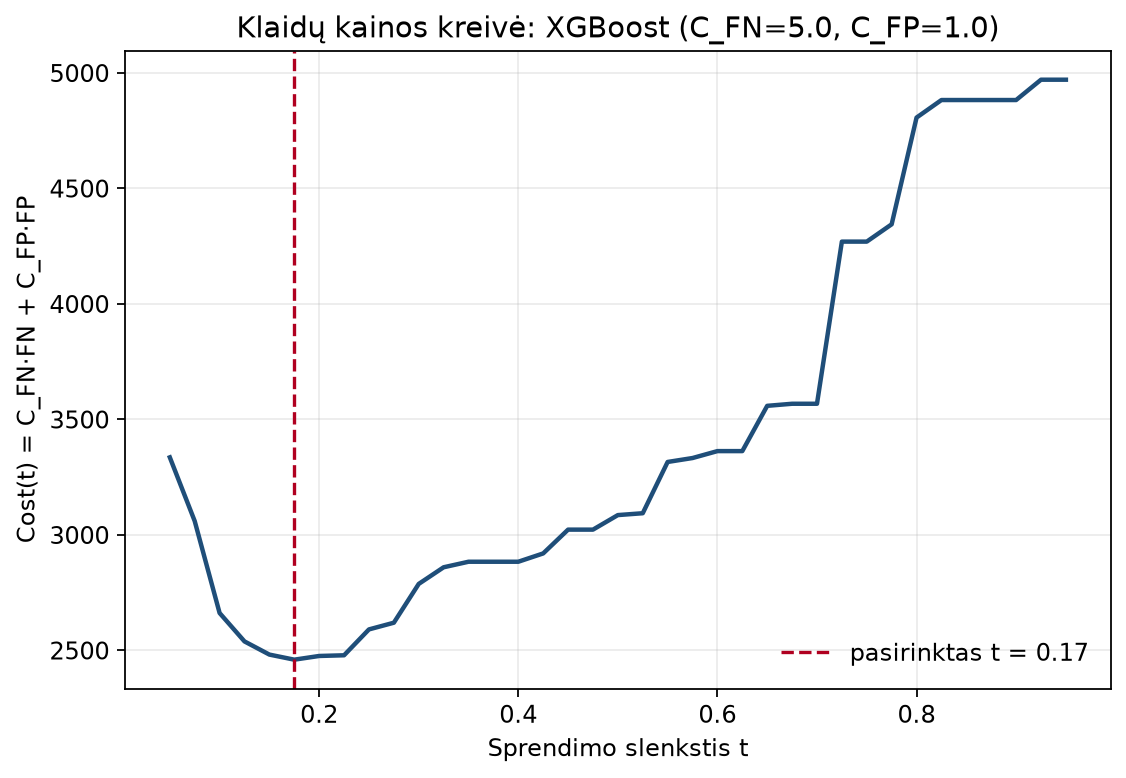

**group_prauc.png**

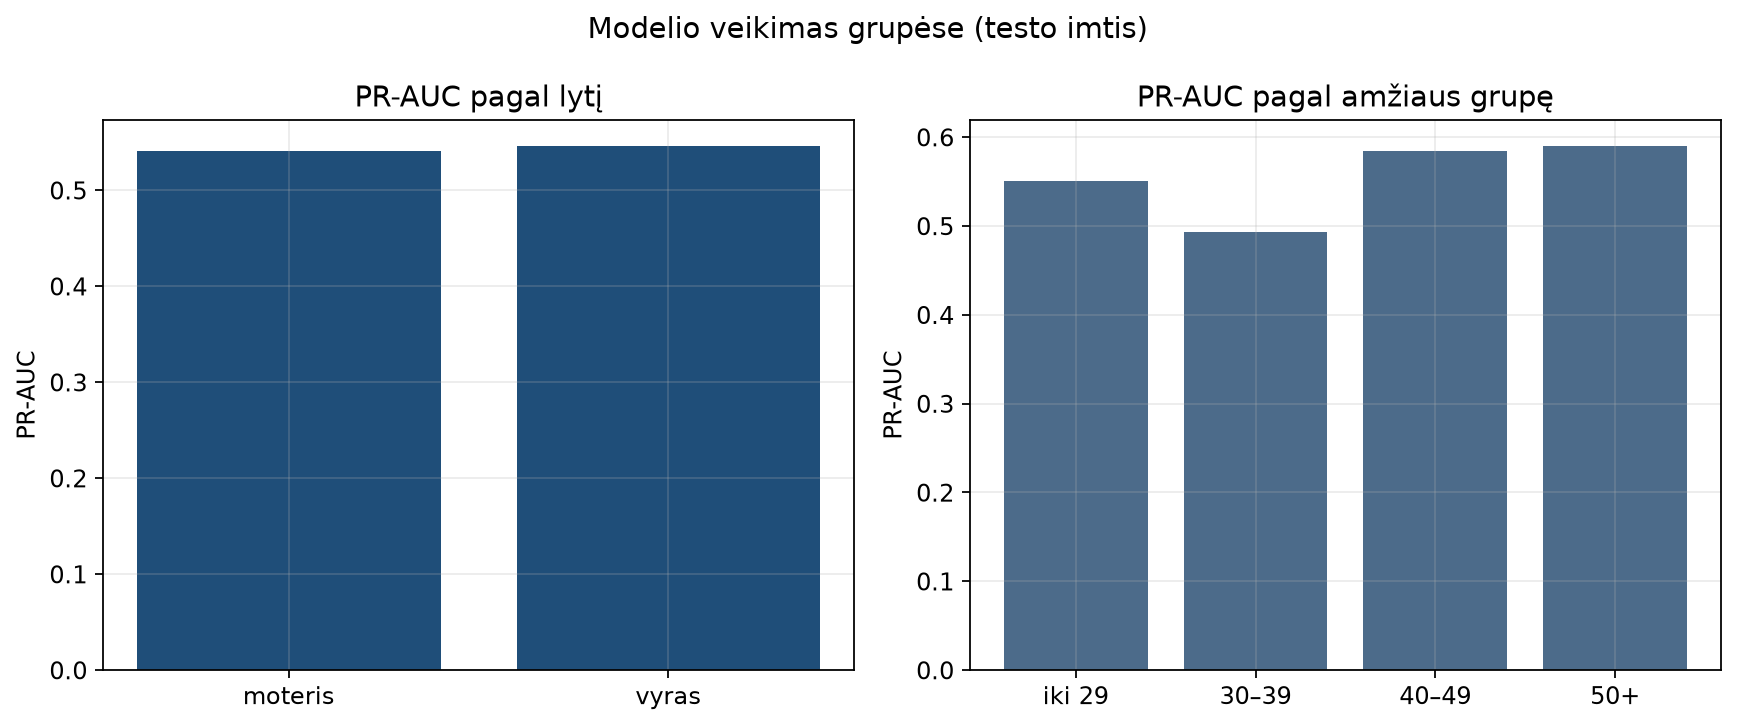

In [5]:
for name in ["pr_curves.png", "model_bars.png", "calibration.png", "cost_curve.png", "group_prauc.png"]:
    path = ARTIFACTS_DIR / "plots" / name
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path)))


## 4. Abliacija, atsparumas ir klaidos

- Abliacija: pašalinta demografija ir mokėjimų būsenos.
- Atsparumas: Gauso triukšmas, 10 % trūkstamų reikšmių, amžiaus grupės poslinkis.
- Klaidos: FN brangesnės (`C_FN=5`) nei FP (`C_FP=1`).


In [6]:
print("Abliacija")
display(pd.read_csv(ARTIFACTS_DIR / "tables" / "ablation.csv"))
print("Atsparumas")
display(pd.read_csv(ARTIFACTS_DIR / "tables" / "robustness.csv"))
print("Klaidų profilis")
display(pd.read_csv(ARTIFACTS_DIR / "tables" / "error_profile.csv"))


Abliacija


,variant,dropped,val_pr_auc,test_pr_auc,test_brier,test_cost,params
0,visi požymiai,—,0.568027,0.562409,0.178843,3298.0,"{'n_estimators': 150, 'max_depth': 3, 'learnin..."
1,be demografijos,"SEX, EDUCATION, MARRIAGE, AGE",0.569897,0.552699,0.173755,3045.0,"{'n_estimators': 250, 'max_depth': 5, 'learnin..."
2,be mokėjimų būsenų,"PAY_1, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6",0.471323,0.446083,0.197363,3129.0,"{'n_estimators': 250, 'max_depth': 5, 'learnin..."


Atsparumas


,scenario,n,pr_auc,brier,ece,cost,recall_at_t
0,švarus testas,4500,0.542992,0.134295,0.017631,2529.0,0.677387
1,Gauso triukšmas σ=0.15·std,4500,0.487451,0.145549,0.042955,2981.0,0.517588
2,10 % trūkstamų reikšmių,4500,0.527078,0.137138,0.022042,2624.0,0.633166
3,grupės poslinkis: amžius ≥ 50,422,0.589908,0.146781,0.037683,274.0,0.679245


Klaidų profilis


,error_type,LIMIT_BAL,AGE,PAY_1,BILL_AMT1,PAY_AMT1
0,FN,175669.781931,36.084112,-0.383178,61193.264798,5270.274143
1,FP,118766.233766,35.807359,0.297619,27121.102814,1800.533550
2,TN,195493.994576,35.530802,-0.404882,60163.091825,8243.220845
3,TP,120682.492582,36.222552,1.135015,45238.532641,2350.419881


In [7]:
print("False negative pavyzdžiai")
display(pd.read_csv(ARTIFACTS_DIR / "tables" / "fn_examples.csv"))
print("False positive pavyzdžiai")
display(pd.read_csv(ARTIFACTS_DIR / "tables" / "fp_examples.csv"))


False negative pavyzdžiai


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,BILL_AMT1,PAY_AMT1,y,p,yhat
0,10733,260000,2,4,2,32,0,169734,6568,1,0.000001,0
1,983,500000,1,1,2,36,-2,45106,81690,1,0.000001,0
2,18899,140000,2,4,2,28,0,108018,1000,1,0.027322,0
3,28994,480000,2,1,1,39,0,98569,10620,1,0.027322,0
4,10671,410000,1,2,2,48,0,28921,5422,1,0.027322,0
5,10650,400000,2,1,2,27,-2,5457,4460,1,0.055046,0
6,16196,400000,2,3,2,35,-2,1432,8132,1,0.055046,0
7,6854,290000,1,3,2,34,0,5451,1200,1,0.055046,0


False positive pavyzdžiai


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,BILL_AMT1,PAY_AMT1,y,p,yhat
0,28748,50000,2,2,1,28,3,2400,0,0,0.900000,1
1,5593,30000,1,2,1,49,3,26319,1800,0,0.900000,1
2,7175,20000,1,2,1,36,2,25274,1700,0,0.800000,1
3,1989,140000,1,2,2,34,2,135949,8408,0,0.800000,1
4,3873,30000,1,3,1,49,2,26343,1500,0,0.800000,1
5,1707,230000,1,1,2,35,2,117277,5800,0,0.777778,1
6,11818,30000,2,2,1,23,2,26795,3300,0,0.777778,1
7,22691,140000,2,3,1,38,2,119715,6000,0,0.777778,1


## 5. Nedidelis pakeitimas gynimui

Žemiau slenkstis perskaičiuojamas keičiant `C_FN` / `C_FP` **be pakartotinio mokymo**.
Tai tinka dėstytojo prašymui „pakeiskite metriką / slenkstį“.


In [8]:
from src.metrics import select_threshold_by_cost
from src.formulas import confusion_counts, total_error_cost, decision_from_threshold

val = pd.read_csv(ARTIFACTS_DIR / "tables" / "val_predictions.csv")
test = pd.read_csv(ARTIFACTS_DIR / "tables" / "test_predictions.csv")
col = "p_cal_XGBoost"
C_FN, C_FP = 10.0, 1.0  # pakeiskite čia
t, _ = select_threshold_by_cost(val["y"], val[col], C_FN, C_FP)
pred = decision_from_threshold(test[col], t)
print("naujas t =", t)
print(confusion_counts(test["y"], pred))
print("cost =", total_error_cost(test["y"], pred, C_FN, C_FP))


naujas t = 0.075
{'TP': 976, 'TN': 547, 'FP': 2958, 'FN': 19}
cost = 3148.0


## 6. Nematytas CSV testas

Dėstytojo failą galima įkelti svetainėje arba čia pakeitus kelią. Pavyzdys: `data/sample_nematytas_testas.csv`.


In [9]:
from src.data import clean_categories, _normalize_columns
from src.metrics import evaluate_probabilities

bundle = joblib.load(ARTIFACTS_DIR / "models" / "XGBoost.joblib")
schema = joblib.load(ARTIFACTS_DIR / "models" / "schema_example.joblib")
extra = pd.read_csv(ROOT / "data" / "sample_nematytas_testas.csv")
extra = clean_categories(_normalize_columns(extra, require_target=False))
X = extra.reindex(columns=list(schema.columns), fill_value=0)
p_cal = bundle["calibrator"].transform(bundle["model"].predict_proba(X))
t = bundle["threshold"]
if "default" in extra.columns:
    m = evaluate_probabilities(extra["default"], p_cal, t, 5.0, 1.0)
    print({k: m[k] for k in ["pr_auc", "brier", "cost", "FN", "FP"]})
pd.DataFrame({"ID": extra.get("ID"), "p_cal": p_cal, "yhat": (p_cal >= t).astype(int)}).head()


{'pr_auc': 0.5790343915343915, 'brier': 0.22363583562030043, 'cost': 30.0, 'FN': 5, 'FP': 5}


,ID,p_cal,yhat
0,1957,0.900000,1
1,986,0.156701,0
2,4244,0.100000,0
3,6903,0.055046,0
4,21200,0.100000,0


## 7. Išvada ir ribos

- Hipotezė **pasitvirtino**: XGBoost PR-AUC teste didesnis nei logistinės regresijos.
- Random Forest artimas XGBoost, bet silpnesnis pagal PR-AUC.
- Mokėjimų būsenos (`PAY_*`) yra svarbiausia požymių grupė – be jų PR-AUC krenta smarkiai.
- Demografijos pašalinimas PR-AUC sumažina nedaug.
- Triukšmas ir trūkstamos reikšmės pablogina metrikas, bet modelis išlieka geresnis už naivų dažnį.
- Duomenys – Taivanas, 2005 m.; tai ne Lietuvos rinkos modelis ir ne automatinis kredito sprendimas.
